# Machine learning stroke prediction


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 30)
data = pd.read_csv('train.csv')

## EDA




**Klas:** Den Haag 2A
**Teamnaam:** Groep 5

| Teamlid | Kaggle-gebruikersnaam |
|---------|-----------------------|
| *Lars* | *larsol55on* |
| *Sven* | *Svenkr-6* |
| *Roemer* | *Breedveldje* |


### 1.1 Kolombeschrijving



De dataset bevat gegevens van patiënten. Het doel is te voorspellen of een patiënt een beroerte (*stroke*) heeft gehad. De originele omschrijvingen zijn in het Engels; hieronder staat per kolom een uitleg in het Nederlands.

### Identificatie en doelvariabele

| Kolom | Type | Uitleg |
|-------|------|--------|
| `id` | Identificatie | Unieke identificatiecode van de patiënt. Dit is geen inhoudelijk kenmerk en heeft dus geen voorspellende waarde. |
| `stroke` | Binair (**target**) | De doelvariabele die we willen voorspellen: `1` = de patiënt heeft een beroerte gehad, `0` = geen beroerte. |

### Numerieke kenmerken

| Kolom | Type | Uitleg |
|-------|------|--------|
| `age` | Numeriek | Leeftijd van de patiënt in jaren. |
| `avg_glucose_level` | Numeriek | Gemiddeld bloedglucosegehalte (bloedsuikerspiegel) van de patiënt. |
| `bmi` | Numeriek | Body mass index: de verhouding tussen gewicht en lengte. |

### Binaire kenmerken

| Kolom | Type | Uitleg |
|-------|------|--------|
| `hypertension` | Binair | Heeft de patiënt hypertensie (hoge bloeddruk)? `0` = nee, `1` = ja. |
| `heart_disease` | Binair | Heeft de patiënt een hartziekte? `0` = nee, `1` = ja. |

### Dummy-kolommen (one-hot encoding)

De categorische kolommen zijn al omgezet naar dummy-kolommen. Elke categorie heeft een eigen kolom met de waarde `1` (de patiënt hoort bij deze categorie) of `0` (niet). Zo kunnen machine learning-modellen met deze gegevens rekenen.

| Kolom | Uitleg |
|-------|--------|
| `gender_Female` | Patiënt is vrouw. |
| `gender_Male` | Patiënt is man. |
| `gender_Other` | Geslacht is "anders". |
| `ever_married_No` | Patiënt is nooit getrouwd geweest. |
| `ever_married_Yes` | Patiënt is ooit getrouwd geweest. |
| `work_type_Govt_job` | Patiënt heeft een overheidsbaan. |
| `work_type_Never_worked` | Patiënt heeft nooit gewerkt. |
| `work_type_Private` | Patiënt werkt in de particuliere sector. |
| `work_type_Self-employed` | Patiënt is zelfstandige. |
| `work_type_children` | Patiënt is een kind (werkt nog niet). |
| `Residence_type_Rural` | Patiënt woont op het platteland. |
| `Residence_type_Urban` | Patiënt woont in de stad. |
| `smoking_status_formerly smoked` | Patiënt heeft vroeger gerookt. |
| `smoking_status_never smoked` | Patiënt heeft nooit gerookt. |
| `smoking_status_smokes` | Patiënt rookt op dit moment. |

> **Let op:** de categorie `Unknown` (rookgedrag onbekend) heeft geen eigen dummy-kolom. Een patiënt met overal `0` bij de drie `smoking_status_`-kolommen heeft dus een onbekende rookstatus.

 Exploratieve Data Analyse — voorspellen van herseninfarct

**Dataset:** `train.csv`  
**Observaties:** 33.550 patiënten  
**Doelvariabele:** `stroke` (0 = geen herseninfarct, 1 = herseninfarct)

### 1. Geschiktheid voor Machine Learning met Scikit-Learn

De dataset voldoet grotendeels al aan de technische minimumeisen voor Scikit-Learn:

| Controle | Resultaat | Beoordeling / actie |
|---|---:|---|
| Aantal observaties | 33.550 | Voldoende voor classificatie. |
| Aantal kolommen | 22 | Hiervan zijn 20 bruikbare kandidaat-features na het verwijderen van `id` en `stroke`. |
| Ontbrekende waarden | 0 | Geen imputatie nodig. |
| Exact dubbele rijen | 0 | Geen actie nodig. |
| Unieke `id`-waarden | 33.550 | `id` is een identifier en moet uit de features worden verwijderd. |
| Oneindige numerieke waarden | 0 | Geen actie nodig. |
| Doelvariabele | Binair, waarden 0 en 1 | Geschikt voor supervised binary classification. |
| Categorische variabelen | Al als dummyvariabelen aanwezig | Technisch direct bruikbaar na conversie van `bool` naar 0/1 indien een model dit vereist. |

#### Noodzakelijke en aanbevolen aanpassingen

1. **Verwijder `id` uit de featurematrix.** Dit nummer identificeert een patiënt, maar heeft geen inhoudelijke medische betekenis. Gebruik van een unieke identifier kan schijnpatronen en slechte generaliseerbaarheid veroorzaken.
2. **Gebruik `stroke` als target en niet als feature.** Definieer dus $$X = \text{data zonder id en stroke}$$ en $$y = \text{stroke}$$.
3. **Zet booleans om naar gehele 0/1-waarden** wanneer het gekozen model of de preprocessing dit vereist: `X = X.astype(int)` voor de booleankolommen.
4. **Pas een gestratificeerde train-test-split toe**, bijvoorbeeld `train_test_split(..., stratify=y)`. De positieve klasse is zeer zeldzaam.
5. **Gebruik ook `StratifiedKFold` bij cross-validatie** zodat elke fold ongeveer dezelfde strokeverhouding behoudt.
6. **Maak schaling onderdeel van een `Pipeline`** bij KNN, Logistic Regression en SVM. Pas een scaler nooit vóór de train-test-split toe: dat veroorzaakt datalekken.
7. **Kies F1-score als primaire evaluatiemaatstaf** in plaats van accuracy. Overweeg tevens `class_weight='balanced'` en/of resampling; voer resampling uitsluitend uit op de trainingsdata of binnen iedere cross-validatiefold.

#### Controle op dummycodering

De groepen `gender`, `ever_married`, `work_type` en `Residence_type` bevatten bij elke patiënt precies één actieve dummy. Bij `smoking_status` zijn bij 10.320 patiënten alle drie de aangeleverde dummies 0. Dit is inhoudelijk de ontbrekende categorie **Unknown**; deze is dus al impliciet gecodeerd als referentiecategorie.

Voor lineaire modellen met een intercept (Logistic Regression en lineaire SVM) is er perfecte multicollineariteit als alle dummies van een volledige categorie tegelijk worden gebruikt. Verwijder dan per groep één referentiedummy, bijvoorbeeld met `OneHotEncoder(drop='first')`, of laat de huidige codering staan voor boommodellen/KNN. In deze dataset is voor `smoking_status` de impliciete 



### 2. Datatypes en basisstatistieken



Voor numerieke kolommen zijn minimum, gemiddelde, mediaan en maximum weergegeven. Voor binaire kolommen betekent het gemiddelde het aandeel met waarde 1/`True`.

| Kolom | Datatype | Ontbrekend | Uniek | Minimum | Gemiddelde | Mediaan | Maximum |
|---|---|---:|---:|---:|---:|---:|---:|
| `id` | int64 | 0 | 33.550 | 1,00 | 36.746,39 | 36.862,00 | 72.943,00 |
| `age` | float64 | 0 | 104 | 0,08 | 41,82 | 43,00 | 82,00 |
| `hypertension` | int64 | 0 | 2 | 0,00 | 0,088 | 0,00 | 1,00 |
| `heart_disease` | int64 | 0 | 2 | 0,00 | 0,043 | 0,00 | 1,00 |
| `avg_glucose_level` | float64 | 0 | 11.241 | 55,01 | 103,59 | 91,32 | 281,59 |
| `bmi` | float64 | 0 | 542 | 10,10 | 28,60 | 27,70 | 97,60 |
| `gender_Female` | bool | 0 | 2 | — | 0,597 | — | — |
| `gender_Male` | bool | 0 | 2 | — | 0,403 | — | — |
| `gender_Other` | bool | 0 | 2 | — | 0,000 | — | — |
| `ever_married_No` | bool | 0 | 2 | — | 0,361 | — | — |
| `ever_married_Yes` | bool | 0 | 2 | — | 0,639 | — | — |
| `work_type_Govt_job` | bool | 0 | 2 | — | 0,124 | — | — |
| `work_type_Never_worked` | bool | 0 | 2 | — | 0,004 | — | — |
| `work_type_Private` | bool | 0 | 2 | — | 0,425 | — | — |
| `work_type_Self-employed` | bool | 0 | 2 | — | 0,153 | — | — |
| `work_type_children` | bool | 0 | 2 | — | 0,145 | — | — |
| `Residence_type_Rural` | bool | 0 | 2 | — | 0,500 | — | — |
| `Residence_type_Urban` | bool | 0 | 2 | — | 0,500 | — | — |
| `smoking_status_formerly smoked` | bool | 0 | 2 | — | 0,169 | — | — |
| `smoking_status_never smoked` | bool | 0 | 2 | — | 0,376 | — | — |
| `smoking_status_smokes` | bool | 0 | 2 | — | 0,148 | — | — |
| `stroke` | int64 | 0 | 2 | 0,00 | 0,015 | 0,00 | 1,00 |

De targetverdeling is 33.033 observaties zonder stroke (98,46%) tegenover 517 observaties met stroke (1,54%). Een model dat steeds klasse 0 voorspelt behaalt daardoor al 98,46% accuracy, maar detecteert geen enkel herseninfarct. Accuracy is daarom geen geschikte hoofdmaatstaf.



### 3. Relaties tussen kenmerken en stroke



#### Numerieke kenmerken

| Kenmerk | Geen stroke: gemiddelde (mediaan) | Stroke: gemiddelde (mediaan) | Pearson-correlatie met `stroke` |
|---|---:|---:|---:|
| Leeftijd | 41,40 (43,0) | 68,54 (72,0) | 0,149 |
| Gemiddeld glucosegehalte | 103,18 (91,22) | 129,45 (104,12) | 0,077 |
| BMI | 28,58 (27,70) | 29,88 (29,00) | 0,021 |
| Hypertensie | 8,81% | 27,85% | 0,084 |
| Hartziekte | 4,04% | 21,28% | 0,105 |

Leeftijd heeft van de onderzochte losse variabelen de sterkste samenhang met stroke. De mediaan ligt 29 jaar hoger bij patiënten met stroke. Het glucosegehalte ligt ook duidelijk hoger in de strokegroep, maar de verdeling is rechts-scheef en bevat hoge waarden. BMI verschilt beperkt tussen beide groepen en heeft vrijwel geen lineaire samenhang met de target.

#### Binaire medische kenmerken

| Kenmerk | Strokepercentage bij 0/Nee | Strokepercentage bij 1/Ja |
|---|---:|---:|
| Hypertensie | 1,22% | 4,87% |
| Hartziekte | 1,27% | 7,62% |

Patiënten met hypertensie hebben circa vier keer zo vaak een stroke als patiënten zonder hypertensie. Voor hartziekte is het strokepercentage ongeveer zes keer zo hoog. Dit zijn associaties, geen bewijs voor causaliteit.

#### Categorische kenmerken: opvallende strokepercentages

| Kenmerk | Categorie | Aantal | Strokepercentage |
|---|---|---:|---:|
| Geslacht | Male | 13.512 | 1,67% |
| Geslacht | Female | 20.032 | 1,45% |
| Burgerlijke staat | Yes | 21.426 | 2,16% |
| Burgerlijke staat | No | 12.124 | 0,45% |
| Werktype | Self-employed | 5.126 | 3,34% |
| Werktype | Private | 19.279 | 1,49% |
| Werktype | children | 4.848 | 0,02% |
| Woonomgeving | Urban | 16.776 | 1,57% |
| Woonomgeving | Rural | 16.774 | 1,51% |
| Rookstatus | formerly smoked | 5.661 | 2,47% |
| Rookstatus | smokes | 4.967 | 1,79% |
| Rookstatus | never smoked | 12.602 | 1,70% |
| Rookstatus | Unknown | 10.320 | 0,72% |

`gender_Other` (n = 6) en `work_type_Never_worked` (n = 141) hebben te weinig observaties om betrouwbare conclusies te trekken. De lage percentages bij `children`, `Unknown` en `ever_married_No` hangen waarschijnlijk sterk samen met leeftijd. Bekijk deze kenmerken daarom niet geïsoleerd: een multivariaat model is nodig om voor zulke samenhang te corrigeren.



### 4. Visualisaties



Gebruik de vier meegeleverde figuren in het notebook:

1. **Klasseverdeling:** toont de ernstige klasse-onbalans.
2. **Boxplots van leeftijd, glucose en BMI:** vergelijken de verdelingen tussen stroke en geen stroke.
3. **Staafdiagrammen met strokepercentages:** tonen de relatie van categorische kenmerken, hypertensie en hartziekte met de target.
4. **Correlatieheatmap:** toont de lineaire relaties tussen de numerieke variabelen en `stroke`.



### 5. Belangrijkste bevindingen




1. De data is schoon: geen missende waarden, dubbele rijen of dubbele identifiers. Na het verwijderen van `id` is de data technisch geschikt voor Scikit-Learn.
2. De target is **extreem ongebalanceerd**: slechts 1,54% van de patiënten heeft een stroke. Gebruik daarom een gestratificeerde validatiestrategie, F1-score en technieken zoals klasseweging of resampling binnen trainingsfolds.
3. **Leeftijd** is het duidelijkste individuele signaal. De groep met stroke is gemiddeld aanzienlijk ouder.
4. **Hartziekte** en **hypertensie** hebben sterke bivariate associaties met stroke; het strokepercentage is respectievelijk 7,62% en 4,87% in de positieve groepen.
5. Een hoger **gemiddeld glucosegehalte** komt vaker voor bij stroke. **BMI** laat daarentegen slechts een zwak verschil zien.
6. Rookstatus, burgerlijke staat en werktype laten verschillen zien, maar deze hangen waarschijnlijk deels samen met leeftijd. Gebruik modellen met meerdere features en controleer prestaties via cross-validatie.
7. De hoge glucose- en BMI-waarden zijn volgens de IQR-regel potentiële uitschieters. Ze zijn medisch plausibel en moeten niet automatisch worden verwijderd. Controleer eventueel robuustheid met `RobustScaler` of vergelijk modellen met en zonder outlierbehandeling.



### 6. Standaardiseren



Standaardiseren zet een continue variabele om naar een z-score:

$$z = \frac{x - \mu}{\sigma}$$

Dit is gewenst voor afstands- en schaalgevoelige modellen: **KNN**, **Logistic Regression** (vooral bij regularisatie) en **SVM**. Zonder schaalverdeling kan `avg_glucose_level` door zijn grotere bereik zwaarder meewegen dan bijvoorbeeld BMI of leeftijd. Pas een `StandardScaler` toe in een `Pipeline`, zodat gemiddelde en standaardafwijking uitsluitend uit de trainingsdata worden geschat.

Voor **Decision Trees**, **Random Forest**, **Gradient Boosting** en **XGBoost** voegt standaardiseren doorgaans geen waarde toe: deze modellen splitsen op drempelwaarden en zijn invariant voor monotone schaaltransformaties.

Een passende basisopzet is:

```python
X = df.drop(columns=["id", "stroke"])
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000))
])
```


## 1.5 Opschonen

### Kolommen

Het model moet gefit worden op data die zo schoon mogelijk is. De features behoren geen ruis te geven. Daarom kijken we naar twee onderdelen

- Onmogelijke correlatie

Sommige informatie kan onmogelijk correleren, of zou niet moeten correleren met de predictor. In dit geval is het de ID kolom. Dit zijn willekeurige cijfers om elke rij te identificeren, alleen het model zal hier patronen proberen te ontdekken die niet bestaan, dit noem je ruis. Om deze reden zullen we de ID kolom weghalen



- Multicolineariteit

Kolommen die naar dummys worden omgezet hebben standaard een sterke correlatie met elkaar --> als het ene waar is, is het andere niet waar --> sterke negatieve correlatie. Dit zorgt ervoor dat de dummykolomen een sterkere weging krijgen zonder dat dat de bedoeling is. We kunnen dit voorkomen door per onderscheiding één klasse weg te halen, waardoor de ontbrekende klasse van toepassing is als de overige 'False' geven. Hieronder is een overzicht gemaakt van de klassen per variabele.




| Variabele | Categorieën |
|---|---|
| **Gender** | `gender_male`, `gender_female`, `gender_other` |
| **ever_married** | `ever_married_No`, `ever_married_Yes` |
| **work_type** | `Govt_job`, `Never_worked`, `Private`, `Self-employed`, `children` |
| **Residence_type** | `Rural`, `Urban` |
| **smoking_status** | `formerly_smoked`, `never_smoked`, `smokes`, `unknown` |


Bij de beschrijving van de opdracht is er aangegeven dat smoking_status al een verwijderde kolom heeft. Daarom hoeft deze variabele niet aangepast te worden.

In [3]:
dropcols = ['id', 'stroke', 'gender_Male', 'ever_married_No', 'work_type_Govt_job', 'Residence_type_Rural']

### Rijen

Om irrelevante rijen te verwijderen kijken we weer naar twee onderdelen

- Missende waarden door geen datagerelateerde reden --> MCAR

De dataset bevat geen missende waarden, dus hier hoeft niks aan te gebeuren.


- Onmogelijke/foute waarden

Hierbij kijken we of er extreem hoge/lage waarden zijn.

Zoals je hieronder kunt zien zijn alle histplots redelijk normaal. Er zijn geen extreme (onrealistische) uitschieters met onmogelijke waarden. 

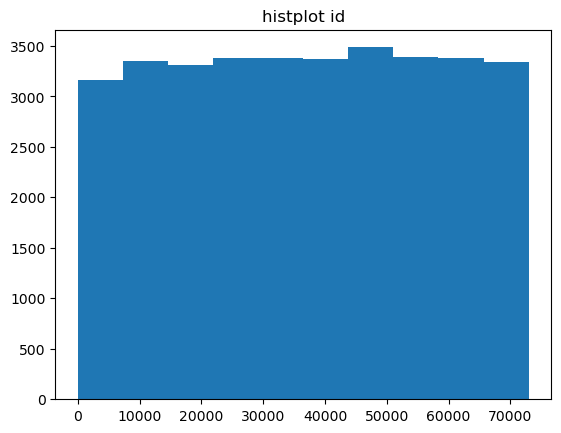

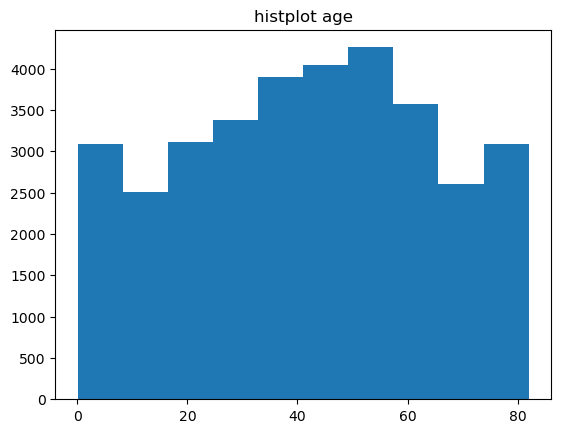

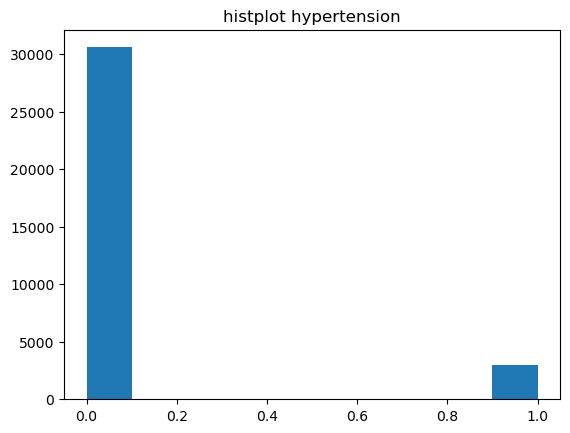

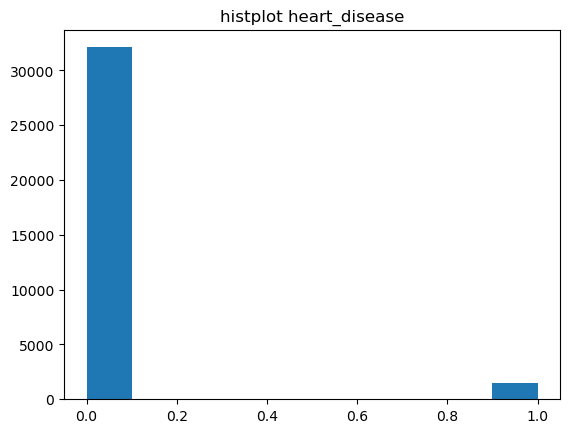

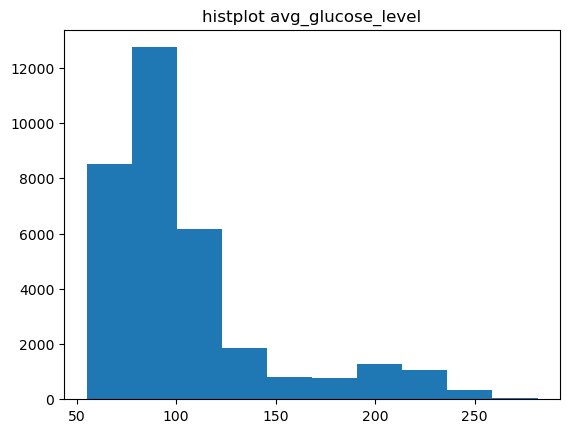

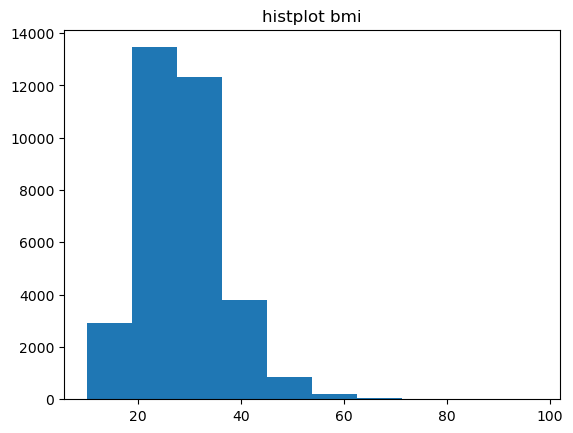

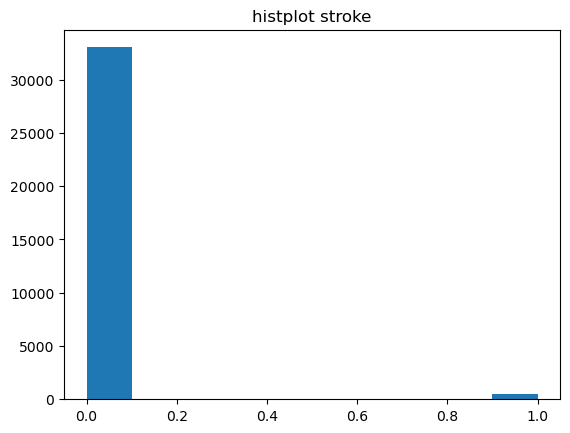

In [4]:
for i in data.select_dtypes(include=["integer", "floating"]).columns:
    plt.hist(data[i])
    plt.title(f"histplot {i}")
    plt.show()

Definitieve opschoning:

In [6]:
df = data.drop(dropcols, axis=1)

## 2. Evaluatie

In dit hoofdstuk bepalen we met welke metrics kan worden gemeten hoe goed een model presteert op het stroke-voorspellingsprobleem. We demonstreren deze metrics aan de hand van een K-Nearest Neighbors (KNN) model.

### 2.1 Welke metrics zijn relevant?

We voorspellen of iemand een herseninfarct krijgt (ja/nee). Dit is dus een **binaire classificatie**. Bovendien is de dataset **imbalanced**: er zijn veel meer patiënten zonder stroke dan met stroke. Dit heeft grote gevolgen voor welke metrics zinvol zijn.

#### Confusion Matrix als basis

Alle metrics komen voort uit vier basiswaarden:

|  | **Voorspeld: Geen stroke** | **Voorspeld: Stroke** |
|---|---|---|
| **Werkelijk: Geen stroke** | True Negative (TN) | False Positive (FP) |
| **Werkelijk: Stroke** | False Negative (FN) ⚠️ | True Positive (TP) |

In een **medische context** is een **False Negative (gemiste stroke) veel erger** dan een False Positive (vals alarm). Een gemiste stroke betekent dat een patiënt met verhoogd risico geen preventieve zorg krijgt.

#### De belangrijkste metrics

**Accuracy**
Het percentage patiënten dat correct voorspeld is. Deze metric is **misleidend bij imbalanced data**: een model dat altijd "geen stroke" voorspelt, haalt al rond de 95% accuracy, maar is in de praktijk waardeloos omdat het geen enkele stroke-patiënt herkent.

**Precision**
Van alle patiënten die het model als "stroke" bestempelt, hoeveel hebben er écht een stroke? Een hoge precision betekent weinig vals alarm.

**Recall (Sensitivity)**
Van alle werkelijke stroke-patiënten, hoeveel vangt het model er op? Deze metric is **zeer belangrijk in deze medische context**, omdat we zo min mogelijk patiënten willen missen.

**F1-score**
Het harmonisch gemiddelde van precision en recall. Deze metric is pas hoog als zowel precision als recall hoog zijn. **Dit is de officiële Kaggle-metric** voor deze competitie.

**ROC-AUC**
De oppervlakte onder de ROC-curve. Deze waarde ligt tussen 0.5 (random gokken) en 1.0 (perfect model). Nuttig om modellen onderling te vergelijken, onafhankelijk van de gekozen drempelwaarde.

**Specificity**
Van alle gezonde mensen, hoeveel worden correct als "geen stroke" aangemerkt? Complementair aan recall.

### 2.2 Waarom F1-score de beste maatstaf is voor dit vraagstuk

In de Kaggle-competitie wordt gekozen voor de F1-score om modellen te beoordelen. Dit is om de volgende redenen de meest geschikte maatstaf:

1. **Accuracy faalt bij imbalanced data.** Omdat ongeveer 95% van de patiënten geen stroke heeft, haalt een model dat niemand als stroke-patiënt classificeert al een zeer hoge accuracy, zonder dat het model enige waarde heeft.
2. **Alleen Precision is niet genoeg.** Dit zou een model belonen dat zelden "stroke" voorspelt (hoge zekerheid), maar daardoor veel patiënten mist.
3. **Alleen Recall is ook niet genoeg.** Dit zou een model belonen dat iedereen als stroke bestempelt (geen gemiste patiënten), maar dat veroorzaakt enorm veel vals alarm.
4. **F1-score dwingt een balans af** tussen precision en recall. Een model moet zowel weinig patiënten missen (recall) als nauwkeurig zijn in zijn positieve voorspellingen (precision) om een goede score te halen.
5. In een medische toepassing is dit een redelijke keuze. In een echte productieomgeving zou men mogelijk nog meer gewicht aan recall willen geven (bijvoorbeeld via de F2-score), omdat een gemiste stroke ernstigere gevolgen heeft dan een vals alarm.

### 2.3 Demonstratie met K-Nearest Neighbors

Hieronder trainen we een eenvoudig KNN-model en berekenen we alle bovenstaande metrics om te laten zien hoe deze zich tot elkaar verhouden op dit probleem.


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
y = train["stroke"]
X = train.drop(["stroke", "id"], axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      
    random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

print(f"Nauwkeurigheid: {accuracy_score(y_test, y_pred):.2%}")
print(classification_report(y_test, y_pred))

c:\Users\schur\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\schur\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\schur\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\schur\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\schur\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Nauwkeurigheid: 98.33%
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      6600
           1       0.00      0.00      0.00       110

    accuracy                           0.98      6710
   macro avg       0.49      0.50      0.50      6710
weighted avg       0.97      0.98      0.98      6710




### Bronvermelding

Scikit-learn developers. (z.d.). *StandardScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html  
Scikit-learn developers. (z.d.). *StratifiedKFold*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html  
Scikit-learn developers. (z.d.). *F1 score*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html
